## Setup for full pipeline and 5-fold CV

In [1]:
# Setup
import numpy as np                # numpy = fast maths on lists of numbers
import pandas as pd               # pandas = tool for working with tables of data
import matplotlib.pyplot as plt   # matplotlib = tool for drawing charts
import seaborn as sns             # seaborn = prettier chart styling
import warnings                   # lets us hide harmless warning messages

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold   # splitting + cross-validation tools
from sklearn.compose import ColumnTransformer           # applies different prep to different columns
from sklearn.pipeline import Pipeline                   # chains prep steps + model into one object
from sklearn.preprocessing import StandardScaler, OneHotEncoder   # scaling numbers / turning categories into 0-1 columns
from sklearn.impute import SimpleImputer                # fills in missing values
from sklearn.linear_model import LogisticRegression     # our first classifier

warnings.filterwarnings("ignore")   # hide harmless warnings so output stays clean
pd.set_option("display.max_columns", 20)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)

print("✅ Libraries loaded — including sklearn.linear_model.LogisticRegression")

✅ Libraries loaded — including sklearn.linear_model.LogisticRegression


## Step 1 — Rebuild the dataset split and preprocessor

In [2]:
# Load and split
df = pd.read_csv("data/credit_card_fraud_2026.csv")
y  = df["is_fraud"]
X  = df.drop(columns=["transaction_id", "is_fraud"])

# Same 80/20 split as Part 1 (same random_state = same split, so results line up)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42,
)

numeric_features = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "card_age_months",
    "customer_age",
    "account_balance_usd",
    "cvv_retry_count",
    "velocity_score",
    "time_of_day_hour",
    "day_of_week",
    "merchant_risk_score",
    "prior_disputes",
]
categorical_features = ["merchant_category", "card_type", "auth_method", "channel", "device_type", "is_foreign_transaction", "is_new_merchant", "used_vpn", "ip_country_mismatch", "billing_shipping_mismatch", "is_ai_generated_scam_attempt"]

# Same preprocessing recipe as Part 1: fill gaps, scale numbers, one-hot the categories
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), categorical_features),
])

print(f"Training set: {len(X_train):,} customers")
print(f"Test set:     {len(X_test):,} customers")
print("Preprocessor ready (median impute + standard scale | mode impute + one-hot)")

Training set: 16,000 customers
Test set:     4,000 customers
Preprocessor ready (median impute + standard scale | mode impute + one-hot)


## Step 2 — Build the full pipeline: preprocessor + model

In [3]:
# Logistic regression — most interpretable classifier; right starting baseline.
# max_iter raised because the default sometimes warns about non-convergence on this dataset.
model = LogisticRegression(max_iter=1000, random_state=42)

# Wrap preprocessor + model in one Pipeline
full_pipeline = Pipeline([
    ("prep",  preprocessor),
    ("model", model),
])

print("✅ Full pipeline built.")
print()
print("Steps in order:")
for name, step in full_pipeline.steps:
    print(f"  · {name:8s}  →  {step.__class__.__name__}")

✅ Full pipeline built.

Steps in order:
  · prep      →  ColumnTransformer
  · model     →  LogisticRegression


## Step 3 — Fit on training data

In [4]:
# .fit() = the actual learning: the model finds the best coefficient for each feature
full_pipeline.fit(X_train, y_train)

print("✅ Pipeline fitted.")
print()
print(f"Training accuracy:   {full_pipeline.score(X_train, y_train):.3f}")   # how often it is right on data it has SEEN
print(f"Test accuracy:       {full_pipeline.score(X_test,  y_test):.3f}")   # how often it is right on data it has NEVER seen
print()
print(f"Baseline (always 'stayed'): {1 - y_test.mean():.3f}  ← anything better than this is learning something.")

✅ Pipeline fitted.

Training accuracy:   0.986
Test accuracy:       0.985

Baseline (always 'stayed'): 0.983  ← anything better than this is learning something.


## Step 4 — Coefficient inspection

Top features ranked by absolute coefficient size:
                           feature  coefficient
     auth_method_No Authentication     1.604343
is_ai_generated_scam_attempt_False    -1.418534
   billing_shipping_mismatch_False    -1.390450
         ip_country_mismatch_False    -1.367299
 is_ai_generated_scam_attempt_True     1.207000
    billing_shipping_mismatch_True     1.178916
          ip_country_mismatch_True     1.155765
             auth_method_Biometric    -1.050704
               merchant_risk_score     0.992172
                    used_vpn_False    -0.895957


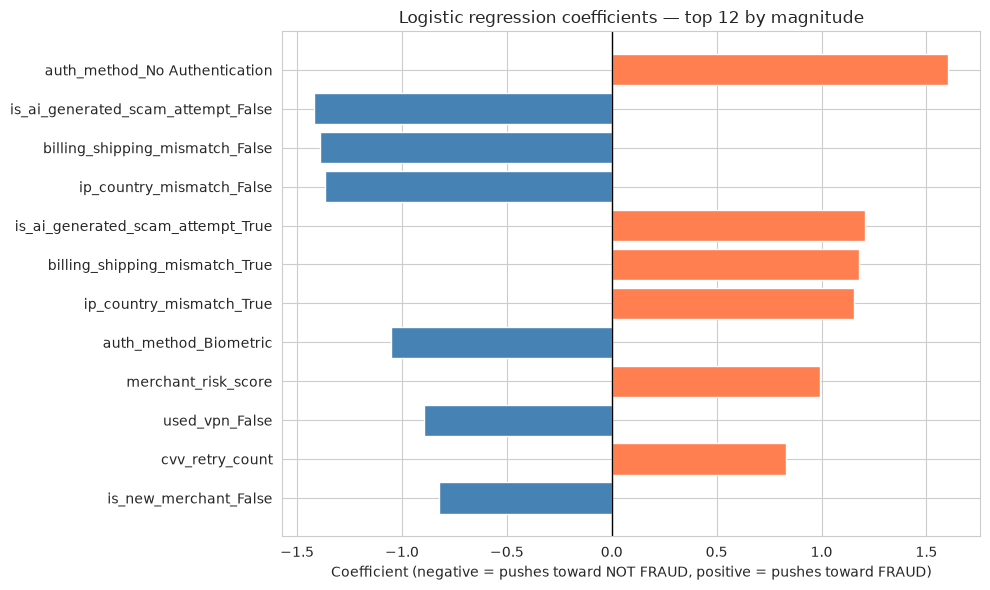

In [5]:
# Grab the trained logistic regression model and the feature names
# Pull the learned coefficients out of the fitted pipeline
feature_names = full_pipeline.named_steps["prep"].get_feature_names_out()
coefs         = full_pipeline.named_steps["model"].coef_[0]

# Build a tidy dataframe sorted by absolute strength
coef_df = pd.DataFrame({
    "feature":     [name.split("__")[-1] for name in feature_names],
    "coefficient": coefs,
    "abs_coef":    np.abs(coefs),
}).sort_values("abs_coef", ascending=False).reset_index(drop=True)

print("Top features ranked by absolute coefficient size:")
print(coef_df[["feature", "coefficient"]].head(10).to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
plot_df = coef_df.head(12).iloc[::-1]
colors  = ["coral" if c > 0 else "steelblue" for c in plot_df["coefficient"]]
ax.barh(plot_df["feature"], plot_df["coefficient"], color=colors, edgecolor="white")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Coefficient (negative = pushes toward NOT FRAUD, positive = pushes toward FRAUD)")
ax.set_title("Logistic regression coefficients — top 12 by magnitude")
plt.tight_layout()
plt.show()

## Step 5 — 5-fold cross-validation

In [7]:
# Cross-validation: split training data into 5 folds; train on 4, validate on 1, rotate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# This trains and scores the whole pipeline 5 times — one score per fold
cv_scores = cross_val_score(
    full_pipeline,
    X_train, y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
)

print(f"5-fold CV accuracy scores: {[f'{s:.3f}' for s in cv_scores]}")
print()
print(f"Mean: {cv_scores.mean():.3f}")
print(f"Std:  {cv_scores.std():.3f}")
print()
print(f"Stable estimate: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
print()
print(f"Versus baseline (always 'stayed'): {1 - y_train.mean():.3f}")
print()
print("→ Cross-validated accuracy is a much more honest number than the single split.")

5-fold CV accuracy scores: ['0.986', '0.983', '0.987', '0.984', '0.984']

Mean: 0.985
Std:  0.001

Stable estimate: 0.985 ± 0.001

Versus baseline (always 'stayed'): 0.983

→ Cross-validated accuracy is a much more honest number than the single split.


## ✅ Section Summary

| What we did | Result |
|---|---|
| **Built the full pipeline** | One sklearn `Pipeline` — preprocess + LogisticRegression — fits and predicts in one call |
| **Fitted on training data** | The line where the model actually learns its parameters |
| **Inspected coefficients** | `auth_method_No Authentication` (+), `is_ai_generated_scam_attempt_False` (-), `billing_shipping_mismatch_False` (−), `ip_country_mismatch_False` (-) drive predictions most, with `is_ai_generated_scam_attempt_True` (+) next — all match intuition |
| **5-fold CV accuracy** | Stable around `~98.3%-98.7%` — but accuracy ≈ baseline because the data is imbalanced |